# Application 4A — cluster geometry, optimization, and stability

**Question:** When do fitted groups match the generating structure?

For K groups, feature vectors $x_i$, and centroids $\mu_k$, **K-means inertia** is
$W=\sum_k\sum_{i\in C_k}\|x_i-\mu_k\|^2$. **Lloyd's algorithm** alternates nearest-center assignments
and group means. Cluster IDs have no intrinsic meaning.

**Silhouette** measures within-group compactness relative to other groups without labels.
**Adjusted Rand index (ARI)** compares partitions: 1 means identical groups up to renaming,
near 0 is chance agreement under its reference model, and negative values are possible.
**Agglomerative clustering** merges groups using a linkage rule.

Audit tiny examples, then Gaussian clouds and rings in matching units (no scaling).
This is descriptive, not classification: generating labels are used only after unsupervised selection.
No download needed. See [lecture](04_clustering_and_pca.pdf) and [solution](Solutions/04_A_cluster_geometry_solution.pdf).

## 1. Audit Lloyd's updates

Start at centers 0,3 for values 0,2,3,9,10,12. `argmin` assigns nearest centers (ties: smaller index);
group means minimize squared error. Keep an old center if its group is empty and stop when centers stop moving.
This example has neither ties nor empty groups; library empty-group handling can differ.

`KMeans.fit` learns centers; `labels_` stores assignments and `inertia_` the objective.
Supply the same initial centers with `n_init=1` to check the full trace and final objective.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

small = np.array([0, 2, 3, 9, 10, 12], dtype=float).reshape(-1, 1)
initial = np.array([[0.0], [3.0]])

def lloyd_steps(inputs, starting_centers, max_iter=20):
    centers = starting_centers.copy()
    distances = np.sum((inputs[:, None, :] - centers[None, :, :]) ** 2, axis=2)
    trace = [distances.min(axis=1).sum()]
    for iteration in range(max_iter):
        distances = np.sum((inputs[:, None, :] - centers[None, :, :]) ** 2, axis=2)
        labels = distances.argmin(axis=1)
        updated = centers.copy()
        for k in range(len(centers)):
            members = inputs[labels == k]
            if len(members) > 0:
                updated[k] = members.mean(axis=0)
        trace.append(np.sum((inputs - updated[labels]) ** 2))
        if np.allclose(updated, centers, atol=1e-12, rtol=0):
            return updated, labels, np.array(trace)
        centers = updated
    raise RuntimeError("Increase max_iter: the teaching loop has not converged.")

centers, labels, trace = lloyd_steps(small, initial)
reference = KMeans(n_clusters=2, init=initial, n_init=1, algorithm="lloyd", tol=1e-12).fit(small)
np.testing.assert_allclose(trace, [167, 78.8, 28/3, 28/3])
assert np.all(np.diff(trace) <= 1e-10)
np.testing.assert_allclose(np.sort(centers[:, 0]), [5/3, 31/3])
np.testing.assert_allclose(reference.inertia_, trace[-1])
assert adjusted_rand_score(labels, reference.labels_) == 1
print("Objective trace:", trace)
print("Final centers:", centers.ravel())

Objective trace: [167.          78.8          9.33333333   9.33333333]
Final centers: [ 1.66666667 10.33333333]


## 2. Audit hierarchical merge heights

`linkage(X,method=...)` returns child indices, height, and merged size; `dendrogram` draws it.
Pass observations, not a square distance matrix. Single/complete/average linkage use minimum/maximum/mean
cross-group distance. Ward minimizes added squared error,
$$\Delta(A,B)=\frac{|A||B|}{|A|+|B|}\|\bar x_A-\bar x_B\|^2.$$
SciPy displays height $\sqrt{2\Delta}$.

For 0,1,4,6, merge 0/1 and 4/6 first. Check final heights 3,6,4.5,$\sqrt{40.5}$ respectively.
Dendrogram leaf order is not a numerical axis.

,linkage,last height
0,single,3.000000
1,complete,6.000000
2,average,4.500000
3,ward,6.363961


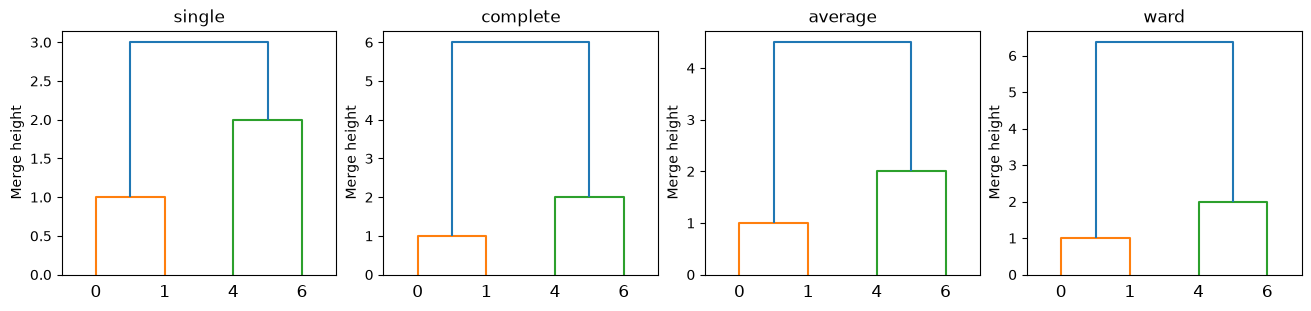

In [2]:
four = np.array([0, 1, 4, 6], dtype=float).reshape(-1, 1)
methods = ["single", "complete", "average", "ward"]
expected = {"single": 3, "complete": 6, "average": 4.5, "ward": np.sqrt(40.5)}
fig, axes = plt.subplots(1, 4, figsize=(13, 3), constrained_layout=True)
height_rows = []
for method, ax in zip(methods, axes):
    merges = linkage(four, method=method, metric="euclidean")
    np.testing.assert_allclose(merges[:, 2], [1, 2, expected[method]])
    height_rows.append({"linkage": method, "last height": merges[-1, 2]})
    dendrogram(merges, labels=["0", "1", "4", "6"], ax=ax)
    ax.set(title=method, ylabel="Merge height")
display(pd.DataFrame(height_rows))
plt.show()

## 3. Select K without generating labels

Generate 600 equally likely Gaussian-component rows centered at (−3,0), (3,0), (0,4), with independent
coordinate noise SD 0.6. For K=2,...,6, `n_init=20` keeps the lowest-inertia initialization.
Select maximum mean Euclidean silhouette (ties: smaller K), then inspect generating-label ARI.
Silhouette uses observation-to-observation distances. Inertia alone cannot select K because extra centers reduce it.

At the selected K, twenty `init="random",n_init=1` runs isolate initialization sensitivity on the same rows.

,K,inertia,silhouette
0,2,2717.381628,0.573511
1,3,441.976378,0.776066
2,4,388.266912,0.595005
3,5,338.064639,0.437117
4,6,288.163173,0.324521


Selected K: 3
Post-selection generating-label ARI: 1.0
Single-start inertia min/median/max: [ 441.97637822  441.97637822 4153.27586419]


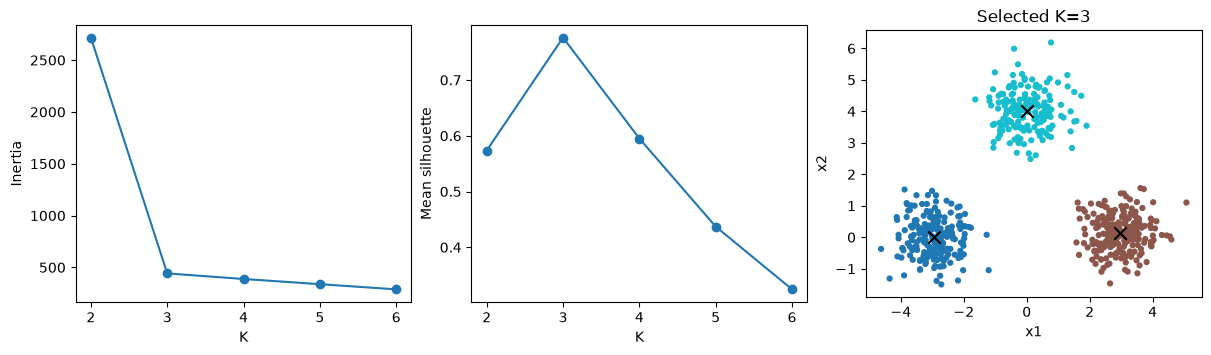

In [3]:
rng = np.random.default_rng(17)
component = rng.integers(0, 3, size=600)
means = np.array([[-3, 0], [3, 0], [0, 4]])
X = means[component] + rng.normal(0, 0.6, size=(600, 2))
fits = {}
rows = []
for K in range(2, 7):
    model = KMeans(n_clusters=K, n_init=20, random_state=23).fit(X)
    fits[K] = model
    rows.append({"K": K, "inertia": model.inertia_, "silhouette": silhouette_score(X, model.labels_)})
selection = pd.DataFrame(rows)
selected_K = int(selection.loc[selection["silhouette"].idxmax(), "K"])
selected = fits[selected_K]
display(selection)
print("Selected K:", selected_K)
print("Post-selection generating-label ARI:", adjusted_rand_score(component, selected.labels_))
restart_inertia = []
for seed in range(20):
    fit = KMeans(n_clusters=selected_K, init="random", n_init=1, random_state=seed).fit(X)
    restart_inertia.append(fit.inertia_)
print("Single-start inertia min/median/max:", np.quantile(restart_inertia, [0, .5, 1]))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)
axes[0].plot(selection["K"], selection["inertia"], "o-")
axes[0].set(xlabel="K", ylabel="Inertia")
axes[1].plot(selection["K"], selection["silhouette"], "o-")
axes[1].set(xlabel="K", ylabel="Mean silhouette")
axes[2].scatter(X[:, 0], X[:, 1], c=selected.labels_, cmap="tab10", s=12)
axes[2].scatter(selected.cluster_centers_[:, 0], selected.cluster_centers_[:, 1], marker="x", c="black", s=80)
axes[2].set(title=f"Selected K={selected_K}", xlabel="x1", ylabel="x2", aspect="equal")
plt.show()

## 4. Compare linkage and group shape

`AgglomerativeClustering(n_clusters=K,linkage=...)` builds/cuts a hierarchy; `fit_predict` labels those rows,
with no built-in new-row `predict`. Use selected K for Gaussian data.
For a separate ring simulation, prespecify K=2: radii 1/3 equally likely, uniform angles, coordinate noise SD 0.05.

Report silhouette and post-fit ARI. Correct ring recovery can have low silhouette because rings are not compact spheres.
Plot colors are arbitrary group IDs.

,data,method,silhouette,ARI
0,Clouds,K-means,0.776066,1.000000
1,Clouds,single,0.776066,1.000000
2,Clouds,complete,0.776066,1.000000
3,Clouds,average,0.776066,1.000000
4,Clouds,ward,0.776066,1.000000
5,Rings,K-means,0.339157,-0.001111
6,Rings,single,0.153329,1.000000
7,Rings,complete,0.343824,0.138083
8,Rings,average,0.319540,0.051850
9,Rings,ward,0.344317,0.113648


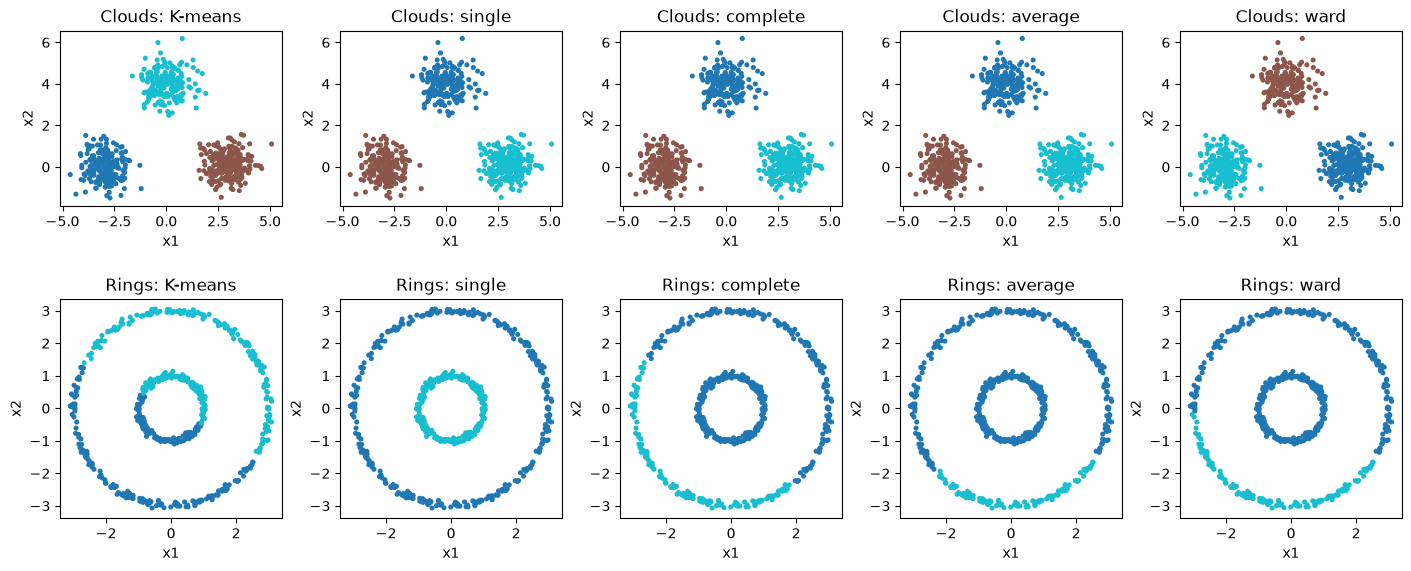

In [4]:
ring_rng = np.random.default_rng(18)
ring_group = ring_rng.integers(0, 2, size=600)
radius = np.where(ring_group == 0, 1.0, 3.0)
angle = ring_rng.uniform(0, 2*np.pi, size=600)
rings = radius[:, None] * np.column_stack([np.cos(angle), np.sin(angle)])
rings += ring_rng.normal(0, 0.05, size=rings.shape)
comparison = []
fig, axes = plt.subplots(2, 5, figsize=(14, 6), constrained_layout=True)
for row, (name, data, truth, K) in enumerate([("Clouds", X, component, selected_K),
                                             ("Rings", rings, ring_group, 2)]):
    models = [("K-means", KMeans(n_clusters=K, n_init=20, random_state=23))]
    models += [(method, AgglomerativeClustering(n_clusters=K, linkage=method)) for method in methods]
    for column, (method, model) in enumerate(models):
        groups = model.fit_predict(data)
        comparison.append({"data": name, "method": method,
                           "silhouette": silhouette_score(data, groups), "ARI": adjusted_rand_score(truth, groups)})
        axes[row, column].scatter(data[:, 0], data[:, 1], c=groups, cmap="tab10", s=7)
        axes[row, column].set(title=f"{name}: {method}", aspect="equal", xlabel="x1", ylabel="x2")
comparison = pd.DataFrame(comparison)
display(comparison)
plt.show()

## 5. Check subsample stability

At fixed selected K, refit K-means with 20 restarts on ten independent 80% subsamples without replacement.
Keep original geometry (no scaler). Compare shared row IDs only; `intersect1d(...,return_indices=True)`
provides their locations in both label arrays.

The 45 pairwise ARIs share fits and are dependent: their quantiles are descriptive, not confidence intervals.
Stability means persistence under this perturbation, not real-world validity.

In [5]:
sampling_rng = np.random.default_rng(23)
subsamples = []
for repeat in range(10):
    ids = np.sort(sampling_rng.choice(len(X), size=480, replace=False))
    fit = KMeans(n_clusters=selected_K, n_init=20, random_state=23).fit(X[ids])
    subsamples.append((ids, fit.labels_))
stability_rows = []
for a in range(len(subsamples)):
    for b in range(a+1, len(subsamples)):
        ids_a, labels_a = subsamples[a]
        ids_b, labels_b = subsamples[b]
        shared, pos_a, pos_b = np.intersect1d(ids_a, ids_b, return_indices=True)
        stability_rows.append({"overlap": len(shared), "ARI": adjusted_rand_score(labels_a[pos_a], labels_b[pos_b])})
stability = pd.DataFrame(stability_rows)
display(stability.describe().loc[["min", "50%", "max"]])
assert adjusted_rand_score(selected.labels_, 10-selected.labels_) == 1
print("Relabeling IDs leaves ARI equal to one.")

,overlap,ARI
min,377.0,1.0
50%,385.0,1.0
max,393.0,1.0


Relabeling IDs leaves ARI equal to one.


## Interpretation and documentation

Explain why the smallest inertia is not a K-selection rule; why a ring can have a low silhouette; and why initialization
sensitivity, subsample stability, and generating-label agreement are different checks. A chain of bridge points can change
single linkage even if the unperturbed rings are recovered perfectly.

Read the official [KMeans API](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.KMeans.html),
[SciPy linkage reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html),
[silhouette definition](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.silhouette_score.html), and
[ARI definition](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.adjusted_rand_score.html).
Set `n_init` explicitly: its automatic default depends on initialization. Do not pass generating labels to a selection metric.